![Banner](../../../Images/Banner/09_distributed_spatial_datas.png)

# Why Spatial Data Outgrow One Core, and What to Do About It

A 90 m elevation model of the Great Plains has 262 million pixels and takes a gigabyte of memory.
The same region in the 10 m Cropland Data Layer has 21 billion pixels, and the whole United States
152 billion. Kansas alone has 1.6 million mapped buildings, and New York City logged 38 million
yellow taxi trips in 2023. Data of this size do not fit comfortably in one Python process, and a
loop over them on one core takes minutes to hours. This notebook explains the ideas that make
such data tractable: chunks and partitions, halos, shuffles, lazy task graphs, GPU memory and
spatial ordering. It then introduces `geolattice.distributed`, the part of GeoLattice that applies
those ideas to rasters and vectors with one API for one core, all cores, a cluster or a GPU, and
measures one terrain operation all four ways.

## Overview

### Two reasons to leave one core

- **Too large.** The data do not fit in memory (the 10 m CDL is 152 GB as bytes), or they fit but
  leave no room for the intermediate arrays an analysis creates. A slope calculation on a 1 GB
  DEM allocates several more gigabytes of temporaries.
- **Too slow.** The data fit, but one core takes too long, or the analysis must be repeated many
  times (999 permutations of a spatial statistic, a model fitted for every fold of a
  cross-validation, a prediction for every pixel).

### Three ways out, and what each costs

| Route | What it gives | What it costs |
|---|---|---|
| All cores of one machine | 8 to 128 workers that share memory | memory bandwidth is shared too; Python's GIL blocks pure Python threads |
| Many machines (a cluster) | memory and cores without a fixed limit | data travel over the network; a scheduler and serialization add overhead |
| A GPU | thousands of simple cores and very fast memory | data must be copied to the device and back over PCIe; device memory is small (8 to 80 GB) |

### Embarrassingly parallel and communication-heavy work

Some spatial operations split cleanly: NDVI, a reclassification or a slope calculation needs only
each pixel (and for slope, its 8 neighbours), so each piece of the raster can be processed alone.
Others need information from far away: flow accumulation depends on every cell upstream, a
spatial join must find every polygon that touches every point, and a weights matrix links each
observation to its neighbours wherever they fall. The first kind scales almost linearly with
workers; the second needs data exchange, and the exchange often limits the speed-up.

### Amdahl's law

If a fraction `p` of the work can run in parallel and the rest is serial, the speed-up on `n`
workers is

`S(n) = 1 / ((1 - p) + p / n)`

With `p = 0.9` the speed-up can never exceed 10, however many cores are added. In geospatial work
the serial part is often reading and decoding files, moving data between host and GPU, or
assembling the result. Measuring where the time goes (notebook 11) matters more than adding
hardware.

### The ideas behind parallel spatial computing

| Idea | Meaning | Spatial example |
|---|---|---|
| **Chunk** (raster) or **partition** (table) | a piece of the data that one task processes | a 2048 x 2048 block of the DEM; 1/24 of the buildings |
| **Halo** (overlap, ghost cells) | extra border pixels a chunk borrows from its neighbours | slope needs 1 pixel, a 9 x 9 mean 4 pixels |
| **Shuffle** | moving rows between partitions so that matching keys meet | taxi trips regrouped by zone; a join of two tables partitioned differently |
| **Lazy task graph** | a recipe of tasks recorded first and run only when a result is asked for | Dask arrays and dask-geopandas frames |
| **Host and device memory** | RAM used by the CPU, and separate memory on the GPU | copying a 1 GB DEM to the GPU takes about 0.15 s over PCIe |
| **Spatial ordering** | sorting features so that neighbours share a partition | a Hilbert curve through building centroids |

### Rasters and vectors differ

A raster is a regular grid: any rectangle of rows and columns is a valid chunk, its neighbours are
known from its position, and a halo of `h` pixels makes a moving window exact. Vector features
have irregular shapes and sizes and no implied neighbours. A partition of polygons can overlap any
other partition, so a spatial join must test pairs of partitions; ordering features along a
space-filling curve keeps each partition compact, and a quick test of partition bounding boxes
(**partition pruning**) rules out most pairs before any geometry is compared.

## Distributed Spatial Computing with GeoLattice

`geolattice.distributed`, imported as `pdist`, gives one API for these routes. Three rules hold
for every function:

1. **`compute="auto" | "cpu" | "gpu"`.** `"auto"` uses the GPU when a CUDA device and a GPU
   implementation exist, otherwise the CPU; asking for `"gpu"` on a machine without one falls back
   to the CPU with a single warning, so notebooks run anywhere.
2. **Same type and memory space out as in.** NumPy in gives NumPy out, a GeoDataFrame gives a
   GeoDataFrame, a CuPy array stays on the GPU, and a lazy Dask input stays lazy.
3. **Local threads unless a session is started.** Without a cluster, Dask's threaded scheduler
   uses every core. `pdist.start("local")`, `pdist.start("cuda")`, `pdist.start("slurm")` and
   friends move the same code onto a cluster (notebook 01).

| Submodule | Operations | Notebook |
|---|---|---|
| sessions, partitioning | `start`, `status`, `plan_chunks`, `spatial_partition`, `partition_bounds` | 00, 01 |
| `io` | `read_raster`, `read_zarr`, `read_stac`, `read_vector`, `write_raster`, `write_vector` | 02 |
| `raster` | `calc`, `where`, `reclassify`, `focal`, `convolve`, `slope`, `aspect`, `hillshade`, `curvature`, `tpi`, `tri`, `roughness`, `map_tiles` | 03 |
| `vector` | `buffer`, `simplify`, `centroid`, `make_valid`, `to_crs`, `area`, `length`, `bounds`, `clip`, `sjoin`, `knn` | 04 |
| `bridge` | `rasterize`, `zonal_stats`, `extract_values`, `polygonize` | 05 |
| `analysis` | `weights`, `morans_i`, `gearys_c`, `local_morans`, `getis_ord_local`, `dbscan`, `hdbscan`, `kmeans`, `kde` | 06 |
| `network` | `graph_from_lines`, `shortest_path`, `shortest_path_lengths`, `centrality`, `components`, `nearest_nodes` | 07 |
| `hydrology` | `flow_direction`, `fill_depressions`, `flow_accumulation` | 08 |
| `ml` | `fit`, `predict_raster`, `predict_tiles`, `train_ddp`, `ddp_model` | 09 |
| `sedona` | `spark`, `to_spark`, `to_geopandas`, `sjoin` | 10 |
| `diagnostics` | `benchmark`, `check_equivalence`, `explain`, `memory_report`, `profile` | 11 |

Behind the API sits a **registry** of operations. Each operation registers a CPU implementation
and, where one exists, a GPU implementation; `pdist.list_ops()` lists them and
`pdist.explain(op)` says which one would run and why.

### Learning objectives

1. Say when data or work outgrow one core, and choose between more cores, a cluster and a GPU.
2. Explain chunks, halos, shuffles, lazy task graphs, host and device memory, and spatial ordering.
3. Apply Amdahl's law to a measured speed-up curve.
4. Use `pdist.capabilities`, `pdist.list_ops` and `pdist.explain` to see what will run where.
5. Compute slope on a 262 million pixel DEM on one core, all cores and a GPU, and check that the
   results agree.
6. Show why a moving window needs a halo, and why vector partitions need spatial ordering.

### Data

| Dataset | Content |
|---|---|
| Great Plains elevation, `Data/03_spatial_analysis/Great_plain/Raster/elev.tif` | 90 m DEM of Colorado, Kansas, New Mexico and Wyoming, 17,196 x 15,245 pixels (262 million), float32, EPSG:5070, 128 x 128 internal tiles |
| Kansas building footprints | 1.6 million Microsoft building polygons from Planetary Computer, cached by `dd.kansas_buildings()` (first run downloads 180 MB) |

### Contents

- Setup
- What this machine has
- The operation registry
- A raster larger than it looks
- Lazy task graphs
- Chunks need halos
- Slope four ways
- Where the GPU time goes
- Amdahl's law in practice
- Vector partitions need spatial order
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import dask  # Dask configuration and schedulers
import dask.array as da  # chunked arrays
import scipy.ndimage as ndi  # whole-array image filters for comparison

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## What this machine has

`pdist.capabilities()` reports which optional engines import and how many CUDA GPUs are visible;
`pdist.memory_report()` reports host and GPU memory.

In [2]:
cap = pd.Series(caps).rename("available")  # engines and GPU count as a column
print(cap.to_string())  # one line per engine
mem = pdist.memory_report()  # host, process and GPU memory in GB
{k: v for k, v in mem.items() if not isinstance(v, dict)}  # the scalar entries

dask                       True
distributed                True
dask_geopandas             True
geopandas                  True
pyarrow                    True
rioxarray                  True
odc.stac                   True
cupy                       True
cudf                       True
dask_cudf                  True
dask_cuda                  True
cuspatial                 False
cugraph                    True
cuml                       True
dask_jobqueue              True
sedona                     True
gpus                          1
gpu_memory_free     16379609088
gpu_memory_total    16760569856


{'backend': 'cpu',
 'host_total_gb': 132.3,
 'host_free_gb': 118.9,
 'process_rss_gb': 0.653,
 'gpu_total_gb': 16.76,
 'gpu_free_gb': 16.38}

This machine has CuPy, cuDF, cuML and cuGraph (the RAPIDS GPU libraries), dask-cuda for GPU
workers, dask-jobqueue and dask-kubernetes for clusters, and Apache Sedona for Spark. cuSpatial is
not installed and not needed: GeoLattice's GPU geometry kernels are written in CuPy. On a laptop
without a GPU the same notebooks run, with `gpus` 0 and every GPU cell falling back to the CPU.

## The operation registry

In [3]:
ops = pd.DataFrame([(op.split(".")[0], op.split(".")[1], ", ".join(t)) for op, t in pdist.list_ops().items()],  # registry as rows
                   columns=["module", "operation", "targets"])  # column names
print(len(ops), "operations;", (ops.targets == "cpu, gpu").sum(), "with a GPU implementation")  # totals
ops.groupby("module").agg(operations=("operation", "size"),  # operations per submodule
                          gpu=("targets", lambda t: int((t == "cpu, gpu").sum())),  # how many have a GPU version
                          names=("operation", lambda s: ", ".join(s)))  # their names

44 operations; 35 with a GPU implementation


,operations,gpu,names
module,,,
analysis,7,7,"dbscan, gearys_c, hdbscan, kde, kmeans, local,..."
bridge,4,3,"extract_values, polygonize, rasterize, zonal_s..."
hydrology,3,1,"fill_depressions, flow_accumulation, flow_dire..."
ml,1,1,predict_raster
network,3,3,"centrality, components, sssp"
raster,15,15,"aspect, calc, convolve, curvature, focal, hill..."
vector,11,5,"area, bounds, buffer, centroid, clip, knn, len..."


In [4]:
for op in ["raster.slope", "bridge.rasterize", "analysis.dbscan", "hydrology.flow_accumulation"]:  # four examples
    e = pdist.explain(op)  # which implementation runs with compute="auto"
    print(f"{op:28s} uses {e['uses']}: {e['reason']}")  # decision and reason
print(pdist.explain("bridge.rasterize", compute="gpu")["uses"], "when compute='gpu' is asked for")  # opt-in GPU

raster.slope                 uses gpu: GPU implementation and 1 GPU(s) available
bridge.rasterize             uses cpu: GPU version is opt-in (slower on typical inputs); pass compute='gpu'
analysis.dbscan              uses cpu: GPU version is opt-in (slower on typical inputs); pass compute='gpu'
hydrology.flow_accumulation  uses cpu: no GPU implementation registered
gpu when compute='gpu' is asked for


Most operations have both versions. Two kinds of exceptions are worth knowing. Some GPU versions
are **opt-in**: measured on typical inputs the CPU was faster (GDAL's scanline fill for
rasterize, scikit-learn's KD-tree for DBSCAN and nearest neighbours, GEOS for simple vector
measures, notebook 04), or the GPU library gave a different answer (cuML's HDBSCAN, notebook 06),
so `"auto"` keeps the CPU and only an explicit `compute="gpu"` uses the device. Depression filling, flow accumulation,
polygonize and the per-feature geometry operations (buffer, simplify, clip) have no GPU version
at all.

## A raster larger than it looks

`pdist.read_raster` opens the DEM lazily: it reads the header, not the pixels, and returns an
xarray DataArray backed by a Dask array cut into chunks.

In [5]:
dem = dd.gp_raster("elev")  # lazy DataArray, 2048 x 2048 chunks
print(f"shape {dem.shape}, {dem.size / 1e6:.0f} million pixels, {dem.dtype}, {dd.gb(dem.nbytes)} in memory")  # size
print(f"chunks {dem.data.chunksize}, {dem.data.npartitions} chunks, is lazy: {pdist.is_lazy(dem)}")  # how it is cut
print("CRS", dem.rio.crs.to_epsg(), "| resolution", dem.rio.resolution())  # georeferencing

shape (17196, 15245), 262 million pixels, float32, 1.05 GB in memory
chunks (2048, 2048), 72 chunks, is lazy: True
CRS 5070 | resolution (90.0, -90.0)


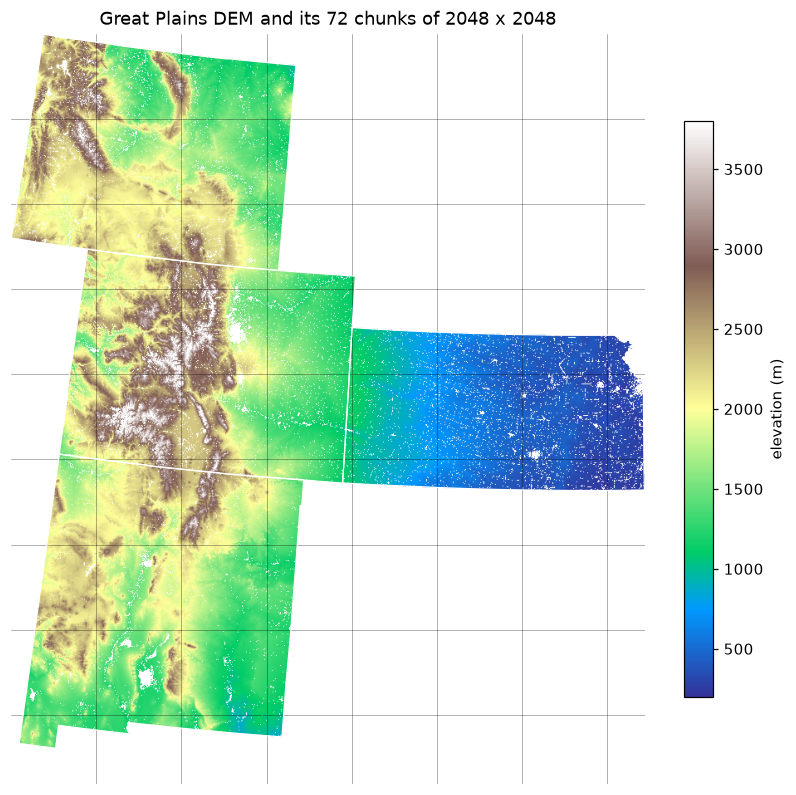

In [6]:
small = dd.quicklook(dem, 20)  # every 20th pixel (1.8 km), computed
fig, ax = plt.subplots(figsize=(7.5, 7.5))  # one map
im = ax.imshow(small, extent=dd.extent(small), cmap="terrain", vmin=200, vmax=3800)  # elevation
plt.colorbar(im, ax=ax, shrink=0.75, label="elevation (m)")  # scale
ys, xs = dem.data.chunks  # chunk sizes along y and x
for e in np.cumsum(xs)[:-1]:  # vertical chunk seams
    ax.axvline(float(dem.x[e]), color="k", lw=0.4, alpha=0.5)  # one line per seam
for e in np.cumsum(ys)[:-1]:  # horizontal chunk seams
    ax.axhline(float(dem.y[e]), color="k", lw=0.4, alpha=0.5)  # one line per seam
dd.gp_states().boundary.plot(ax=ax, color="w", lw=0.8)  # state outlines
ax.set_title(f"Great Plains DEM and its {dem.data.npartitions} chunks of 2048 x 2048"); ax.set_axis_off()  # title
plt.tight_layout(); plt.show()  # draw

Each square is one chunk, the unit of work Dask hands to a worker. About half the pixels lie
outside the four states and are NaN, and small no-data holes are scattered inside them. A whole chunk of NaN still costs a read and a task, which is
one reason cropped or masked data are cheaper than their rectangle suggests.

## Lazy task graphs

Calling a function on a lazy input records tasks instead of computing. The slope below is
returned almost instantly, as a recipe of read, overlap and slope tasks per chunk; it runs when
`.compute()` (or plotting, or writing) asks for numbers.

In [7]:
t = time.perf_counter()  # start the clock
s_lazy = pdist.raster.slope(dem, compute="cpu")  # lazy: records tasks, computes nothing
print(f"built in {time.perf_counter() - t:.3f} s | lazy: {pdist.is_lazy(s_lazy)} | "  # nearly free
      f"{len(s_lazy.data.__dask_graph__())} tasks for {s_lazy.data.npartitions} output chunks")  # graph size
layers = s_lazy.data.__dask_graph__().layers  # the high-level graph, one layer per step
print([k.split("-")[0] for k in layers])  # the steps in order

built in 0.005 s | lazy: True | 1631 tasks for 72 output chunks
['concatenate', 'concatenate', 'original', 'open_rasterio', 'getitem', 'rechunk', 'getitem', 'getitem', 'getitem', 'getitem', 'overlap', 'getitem', 'lambda', '_trim']


In [8]:
with dd.timer("slope of the lazy DEM, read from disk and computed on all cores"):  # time the whole chain
    s_all = s_lazy.compute()  # run the graph
print(type(s_all.data).__name__, f"{dd.gb(s_all.nbytes)}, mean slope {float(s_all.mean()):.2f} degrees")  # in memory now

slope of the lazy DEM, read from disk and computed on all cores: 2.35 s


ndarray 1.05 GB, mean slope 4.48 degrees


The graph has a few tasks per chunk: one to read it, a few to share edge pixels with its
neighbours (the halo, next section), and one to compute slope. Dask runs them on all cores as
soon as their inputs are ready, reading one chunk while computing another.

## Chunks need halos

Slope at a pixel uses its 8 neighbours, and a 9 x 9 moving mean uses 80. A chunk processed on its
own lacks the neighbours that lie in the next chunk, so its edge pixels come out wrong. The fix is
a **halo**: each chunk borrows `h` rows and columns from its neighbours, computes, and trims them
again. `pdist.raster` adds the halo every moving-window operation needs. The cell below compares
three 9 x 9 means on a 4096 x 4096 window: the whole array at once (the reference), chunks without
a halo, and `pdist.raster.focal`.

In [9]:
win = dem[6000:10096, 6000:10096].compute()  # a 4096 x 4096 window in memory
win = win.fillna(float(win.mean()))  # fill the scattered no-data holes (same input for every method)
ref = ndi.uniform_filter(win.values, 9, mode="nearest")  # whole-array 9 x 9 mean: the reference
naive = da.from_array(win.values, chunks=1024).map_blocks(  # 16 chunks, each filtered alone
    lambda b: ndi.uniform_filter(b, 9, mode="nearest")).compute()  # no halo
halo = pdist.raster.focal(win, "mean", size=9, chunks=(1024, 1024))  # GeoLattice adds a 4 pixel halo
for name, r in [("chunks without a halo", naive), ("pdist.raster.focal", halo.values)]:  # compare both
    bad = np.abs(r - ref) > 1e-3  # pixels that differ from the reference
    print(f"{name:24s} wrong pixels: {bad.sum():7d} ({bad.mean():.2%}), largest error {np.abs(r - ref).max():.2f} m")  # error

chunks without a halo    wrong pixels:  165261 (0.99%), largest error 208.12 m
pdist.raster.focal       wrong pixels:       0 (0.00%), largest error 0.00 m


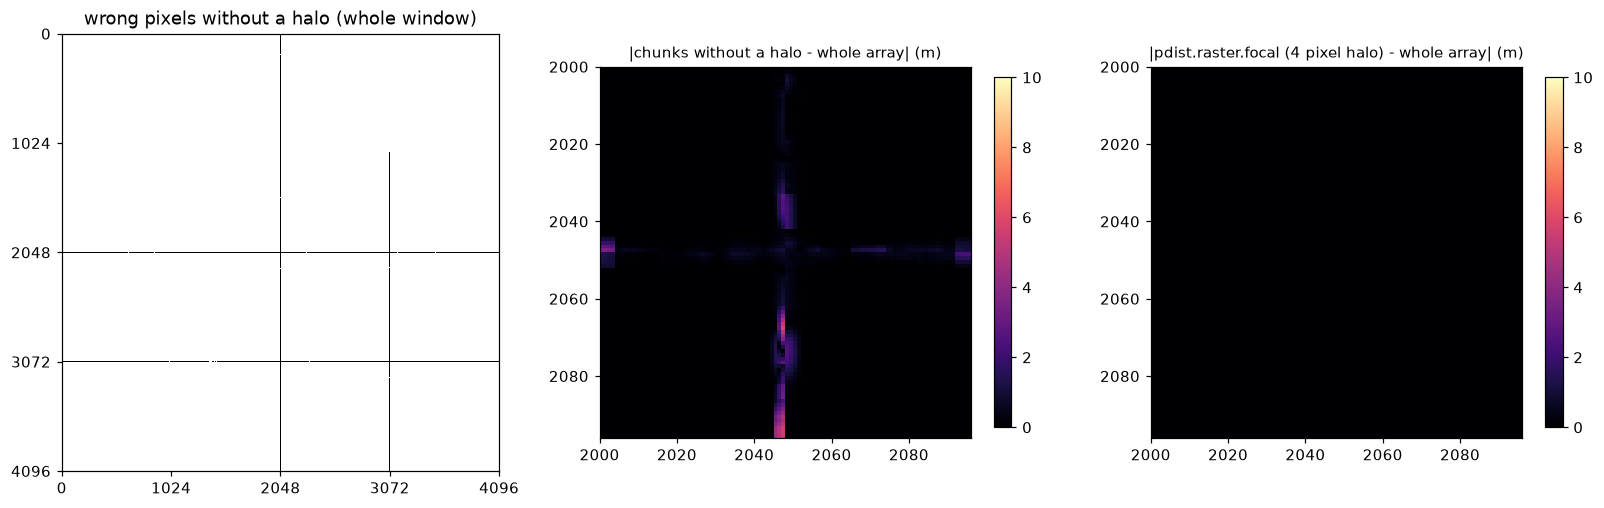

In [10]:
z = (slice(2048 - 48, 2048 + 48), slice(2048 - 48, 2048 + 48))  # 96 x 96 pixels around a seam crossing
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))  # three panels
im = ax[0].imshow(np.abs(naive - ref) > 1e-3, cmap="Greys", interpolation="nearest")  # where the no-halo result is wrong
ax[0].set_title("wrong pixels without a halo (whole window)")  # whole window
ax[0].set_xticks(np.arange(0, 4097, 1024)); ax[0].set_yticks(np.arange(0, 4097, 1024))  # chunk seams as ticks
for a, r, t in [(ax[1], naive, "chunks without a halo"), (ax[2], halo.values, "pdist.raster.focal (4 pixel halo)")]:  # zoomed errors
    im = a.imshow(np.abs(r - ref)[z], cmap="magma", vmin=0, vmax=10, interpolation="nearest",  # error in metres
                  extent=[2000, 2096, 2096, 2000])  # pixel coordinates
    a.set_title(f"|{t} - whole array| (m)", fontsize=10); plt.colorbar(im, ax=a, shrink=0.8)  # labels
plt.tight_layout(); plt.show()  # draw

Without a halo the errors form a grid of lines along the chunk seams wherever the terrain is not
flat, four pixels wide on each side of every seam (the zoom shows the crossing at pixel 2048, 2048); with the halo the chunked
result equals the whole-array result everywhere, edges included.
The halo is not free: it adds reads and data copies proportional to the chunk perimeter, so the
library keeps chunks at least eight halo widths wide (`pdist.plan_chunks`).

## Slope four ways

Now the same slope on the whole in-memory DEM, computed four ways:

1. **one core**: Dask's synchronous scheduler runs the chunks one after another;
2. **all cores**: the default threaded scheduler (NumPy and SciPy release the GIL, so threads
   run in parallel);
3. **GPU from host**: `compute="gpu"` copies each chunk to the GPU, computes there and copies the
   result back, because a host input must give a host output;
4. **GPU resident**: the DEM is moved to the GPU once with `pdist.to_gpu`, and the result stays
   there.

In [11]:
d = dem.compute()  # the DEM in host memory (1 GB)
d_gpu = pdist.to_gpu(d) if caps["gpus"] else None  # a copy in GPU memory, if there is a GPU


def sync():  # wait until the GPU has finished, so timings are real
    if caps["gpus"]:  # only with a GPU
        import cupy as cp  # GPU arrays
        cp.cuda.Device().synchronize()  # block until queued kernels finish


def best_of(fn, n=3):  # best wall time of n runs after one warm-up run
    fn(); sync()  # warm-up: compile kernels, fill caches
    times = []  # timings
    for _ in range(n):  # timed runs
        t = time.perf_counter(); fn(); sync(); times.append(time.perf_counter() - t)  # one run
    return min(times)  # best run


runs = {}  # seconds per way
with dask.config.set(scheduler="synchronous"):  # one task at a time
    runs["one core"] = best_of(lambda: pdist.raster.slope(d, compute="cpu"))  # NumPy, one core
runs[f"all {os.cpu_count()} cores"] = best_of(lambda: pdist.raster.slope(d, compute="cpu"))  # NumPy, threads
if caps["gpus"]:  # GPU timings only where a GPU exists
    runs["GPU from host"] = best_of(lambda: pdist.raster.slope(d, compute="gpu"))  # copies in and out
    runs["GPU resident"] = best_of(lambda: pdist.raster.slope(d_gpu, compute="gpu"))  # stays on the device
t4 = pd.Series(runs, name="seconds").to_frame()  # table
t4["speed-up vs one core"] = t4.seconds.iloc[0] / t4.seconds  # relative speed
t4["Mpixels per s"] = d.size / 1e6 / t4.seconds  # throughput
t4.round(2)  # show

,seconds,speed-up vs one core,Mpixels per s
one core,4.25,1.00,61.74
all 24 cores,2.05,2.07,127.88
GPU from host,0.77,5.52,340.89
GPU resident,0.17,24.75,1528.06


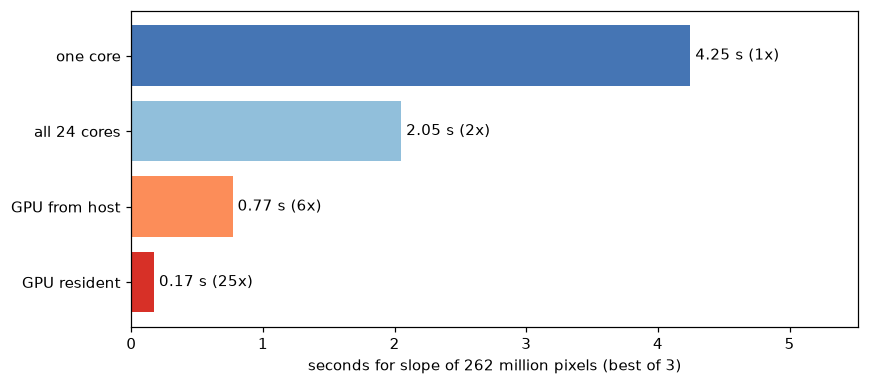

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))  # one panel
ax.barh(t4.index[::-1], t4.seconds[::-1], color=["#4575b4", "#91bfdb", "#fc8d59", "#d73027"][:len(t4)][::-1])  # bars
for i, (s, x) in enumerate(zip(t4.seconds[::-1], t4["speed-up vs one core"][::-1])):  # labels
    ax.text(s, i, f" {s:.2f} s ({x:.0f}x)", va="center")  # time and speed-up
ax.set_xlabel("seconds for slope of 262 million pixels (best of 3)"); ax.set_xlim(0, t4.seconds.max() * 1.3)  # axis
plt.tight_layout(); plt.show()  # draw

All cores were only about twice as fast as one core here: slope does little arithmetic per byte,
so the cores spend most of their time waiting for memory, and every core shares the same memory
bus. The GPU has its own, much faster memory, and with the DEM already on the device it was about
an order of magnitude faster than all CPU cores. Copying a gigabyte in and a gigabyte back costs
more than the computation, so "GPU from host" lands between the two. The lesson recurs in every
notebook: **keep data on the GPU across several operations**, and move it only at the start and
the end.

`pdist.check_equivalence` runs a function on each target and compares the results; the CPU and
GPU slopes agree to float32 rounding.

In [13]:
rep = pdist.check_equivalence(pdist.raster.slope, d, rtol=1e-4, atol=1e-3)  # CPU vs GPU on the full DEM
print("equivalent:", rep.ok, "| largest difference", f"{rep.max_abs:.2e} degrees")  # verdict
print(*rep.details, sep="\n")  # what was compared

equivalent: True | largest difference 1.53e-05 degrees
ok  gpu vs cpu: allclose max_abs=1.53e-05


## Where the GPU time goes

Splitting the "GPU from host" run into its three parts shows why transfers matter.

In [14]:
if caps["gpus"]:  # needs a GPU
    import cupy as cp  # GPU arrays
    parts = {}  # seconds per step
    t = time.perf_counter(); g = cp.asarray(d.values); sync(); parts["copy to GPU"] = time.perf_counter() - t  # host to device
    gda = d.copy(data=g)  # the same DataArray around GPU data
    pdist.raster.slope(gda, compute="gpu"); sync()  # warm-up
    t = time.perf_counter(); r = pdist.raster.slope(gda, compute="gpu"); sync(); parts["slope on GPU"] = time.perf_counter() - t  # compute
    t = time.perf_counter(); h = r.data.get(); parts["copy to host"] = time.perf_counter() - t  # device to host
    parts = pd.Series(parts, name="seconds")  # table
    print(parts.round(3).to_string()); print(f"PCIe throughput about {d.nbytes / parts['copy to GPU'] / 1e9:.1f} GB/s")  # transfer speed
    del g, gda, r, h  # free GPU memory

copy to GPU     0.137
slope on GPU    0.173
copy to host    0.166
PCIe throughput about 7.7 GB/s


## Amdahl's law in practice

The threaded run can be repeated with 1, 2, 4, ... workers. Fitting Amdahl's law to the measured
speed-ups estimates the parallel fraction `p` of this workload on this machine.

In [15]:
from scipy.optimize import curve_fit  # least-squares fit

workers = [1, 2, 4, 8, 12, 16, os.cpu_count()]  # thread counts to try
secs = []  # best time per count
for n in workers:  # each thread count
    with dask.config.set(scheduler="threads", num_workers=n):  # n threads
        secs.append(best_of(lambda: pdist.raster.slope(d, compute="cpu", chunks=(1024, 1024)), n=2))  # time it
speed = secs[0] / np.array(secs)  # measured speed-up
amdahl = lambda n, p: 1 / ((1 - p) + p / n)  # the law
p_fit, _ = curve_fit(amdahl, np.array(workers, float), speed, p0=[0.9], bounds=(0, 1))  # fitted parallel fraction
print("seconds:", dict(zip(workers, np.round(secs, 2))), f"| fitted p = {p_fit[0]:.2f}")  # results

seconds: {1: np.float64(3.77), 2: np.float64(2.27), 4: np.float64(1.62), 8: np.float64(1.7), 12: np.float64(1.85), 16: np.float64(1.98), 24: np.float64(1.95)} | fitted p = 0.57


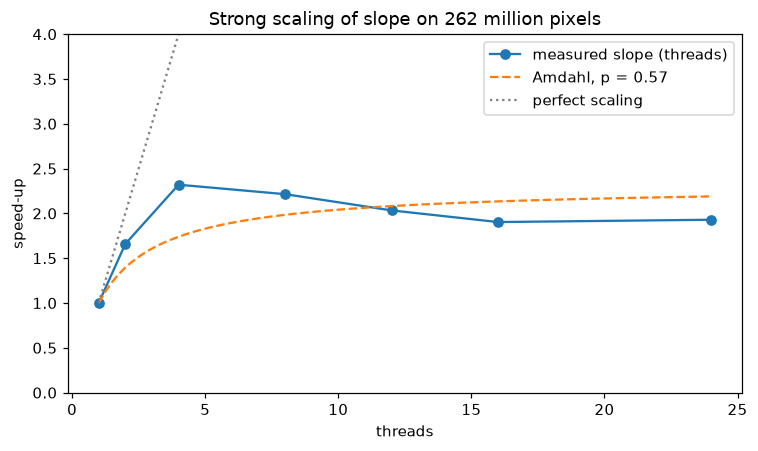

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.2))  # one panel
nn = np.linspace(1, max(workers), 100)  # smooth curve
ax.plot(workers, speed, "o-", label="measured slope (threads)")  # data
ax.plot(nn, amdahl(nn, p_fit[0]), "--", label=f"Amdahl, p = {p_fit[0]:.2f}")  # fitted law
ax.plot(nn, nn, ":", color="grey", label="perfect scaling")  # ideal
ax.set_ylim(0, max(4, speed.max() * 1.5)); ax.set_xlabel("threads"); ax.set_ylabel("speed-up")  # axes
ax.legend(); ax.set_title("Strong scaling of slope on 262 million pixels"); plt.tight_layout(); plt.show()  # draw

The curve peaks at about four threads and then falls slightly. Amdahl's law fits it with a
parallel fraction near 0.6, as if 40 % of the work were serial. Little of slope is really serial;
the limit is memory bandwidth. Slope does a few additions per pixel, so a handful of cores already
saturate the memory bus, and more threads only add contention. A compute-heavy operation (a 9 x 9 median, a model prediction)
scales much better, as notebooks 03 and 09 show. Either way, measure before buying hardware.

## Vector partitions need spatial order

For vectors the unit of work is a **partition**: a slice of the rows. `pdist.spatial_partition`
cuts a GeoDataFrame into partitions; with `method="none"` the rows keep their current order, with
`method="hilbert"` they are first sorted along a Hilbert curve, which visits nearby places
consecutively. `pdist.partition_bounds` returns each partition's bounding box. The building cache
was written Hilbert-sorted already (`pdist.write_vector` does that by default), so the cell below
draws a random sample, whose rows are in arbitrary order, as rows sorted by an attribute or an ID
would be.

In [17]:
bld = dd.kansas_buildings()  # 1.6 million building polygons (downloads once)
pts = bld.set_geometry(bld.geometry.representative_point()).to_crs(5070).sample(200_000, random_state=0)  # a sample of points inside them
print(f"{len(bld):,} buildings; using {len(pts):,} sample points")  # sizes
parts = {m: pdist.spatial_partition(pts, 24, method=m) for m in ["none", "hilbert"]}  # 24 partitions each way
for m, p in parts.items():  # both methods
    b = pdist.partition_bounds(p)  # (24, 4) bounding boxes
    area = ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])).sum() / 1e6  # summed bounding-box area, km2
    print(f"{m:8s} sum of partition bounding boxes {area:12,.0f} km2 ({area / 213_100:.1f} x the area of Kansas)")  # compactness

1,605,334 buildings; using 200,000 sample points
none     sum of partition bounding boxes    5,380,857 km2 (25.3 x the area of Kansas)
hilbert  sum of partition bounding boxes      300,673 km2 (1.4 x the area of Kansas)


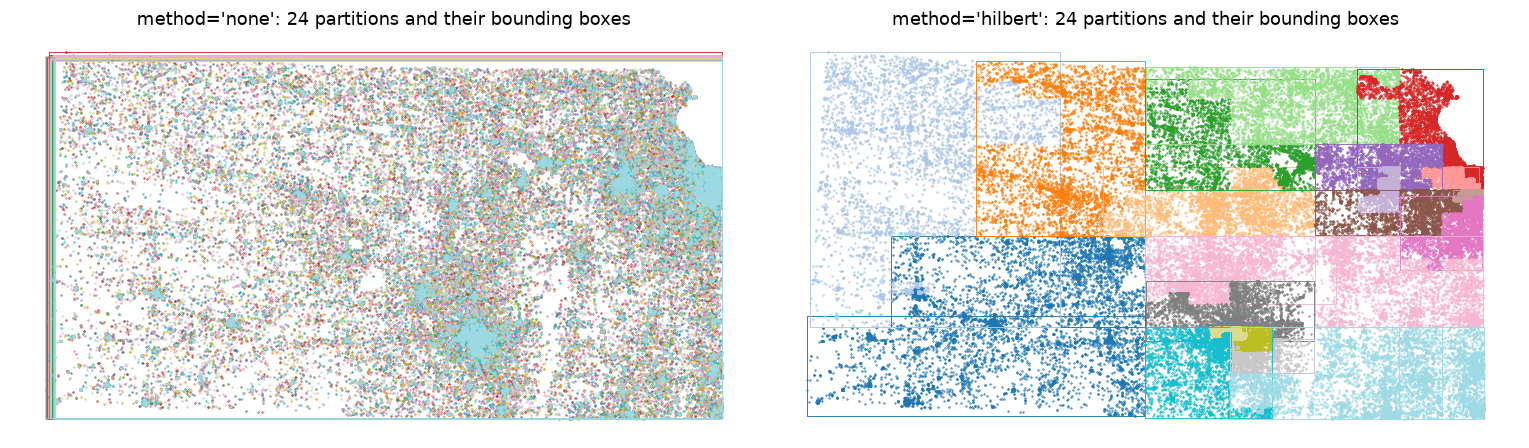

In [18]:
from matplotlib.patches import Rectangle  # boxes

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))  # two maps
cmap = plt.get_cmap("tab20", 24)  # one colour per partition
for ax, (m, p) in zip(axs, parts.items()):  # both methods
    for i, part in enumerate(p):  # each partition
        ax.scatter(part.geometry.x, part.geometry.y, s=0.2, color=cmap(i))  # its points
        x0, y0, x1, y1 = part.total_bounds  # its bounding box
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=0.6, color=cmap(i)))  # draw it
    ax.set_title(f"method='{m}': 24 partitions and their bounding boxes"); ax.set_aspect("equal"); ax.set_axis_off()  # title
plt.tight_layout(); plt.show()  # draw

In arbitrary order every partition holds points from the whole state, so all 24 bounding boxes
cover Kansas and each overlaps all the others. After Hilbert sorting each partition covers a
compact patch, and the summed bounding-box area falls from 25 times to 1.4 times the area of the
state. That is what makes a partitioned spatial join fast (notebook 04): a
partition of points needs only the polygons whose boxes touch its own box.

## Summary and exercises

- Data outgrow one core when they do not fit in memory or one core is too slow; the routes out are
  all cores, a cluster and a GPU, each with its own costs (shared memory bandwidth, network and
  serialization, PCIe transfers and small device memory).
- Rasters split into chunks; moving windows need a halo, without which errors line every chunk
  seam. Vector partitions need spatial ordering so that bounding boxes stay compact.
- Lazy task graphs record work and run it on demand; building the slope graph of 72 chunks took a
  fraction of a millisecond per task.
- On this machine slope of 262 million pixels took a few seconds on one core, about half that on
  all cores, and a fraction of a second on the GPU when the data stayed there. Copies to and from
  the GPU cost more than the computation.
- `pdist.capabilities`, `pdist.list_ops`, `pdist.explain` and `pdist.check_equivalence` show what
  will run where and confirm that CPU and GPU agree.

**Exercises**

1. Repeat the slope timing with `chunks=(512, 512)` and `chunks=(8192, 8192)`. Which is fastest on
   all cores, and why are both extremes slower?
2. Time `pdist.raster.focal(d, "median", size=9)` on all cores and on the GPU. Is the speed-up
   larger or smaller than for slope? Fit Amdahl's law to its thread scaling.
3. Use the halo experiment with `pdist.raster.tpi(win, window=21)`. How wide is the band of wrong
   pixels without a halo?
4. Partition the building sample into 6, 24 and 96 partitions with both methods and plot the
   summed bounding-box area against the number of partitions.